# run_python: giving Escalator a code runner on AWS Lambda

Escalator is a Strands agent where a 2B decision model sends easy questions to Amazon Nova Micro and hard ones to Claude Haiku 4.5 on Amazon Bedrock. The decider can tell whether an answer addresses the question, but not whether a calculation is right. This notebook covers the one tool added for the weekend challenge: `run_python`, which runs model-written Python in an AWS Lambda sandbox.

It runs without AWS. The sandbox code is called locally (the same `handler` that Lambda runs), and the benchmark section reads the saved results in `bench/reported/`. The last section calls Lambda and Bedrock for real; it is off unless you set `RUN_LIVE = True`.

Code: https://github.com/Swayam-Ch/escalator/tree/run-python-tool · Video: https://youtu.be/3geFHbr-2kY

In [1]:
import json
import os
import sys
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "bench"), str(ROOT / "lambda" / "run_python")]

from handler import handler                      # what AWS Lambda runs
from escalator.tools import RunBudget, fix_escaped_newlines, format_result, make_run_python
from run_tool_bench import short, summarise

RUN_LIVE = False   # True invokes the deployed Lambda function and Amazon Bedrock (a few cents)

## 1. The sandbox

`lambda/run_python/handler.py` runs the program in a child process with an empty environment and a time limit, and returns what it printed. Here it is called directly, with the same event Lambda receives.

In [2]:
handler({"code": "print(48917 * 7382)"})

{'stdout': '361105294\n', 'stderr': '', 'exit_code': 0, 'timed_out': False}

The function's own AWS credentials are environment variables inside Lambda. The child process gets an empty environment, so model-written code can't read them:

In [3]:
os.environ["AWS_SECRET_ACCESS_KEY"] = "pretend-this-is-the-lambda-role-key"
handler({"code": "import os; print(os.environ.get('AWS_SECRET_ACCESS_KEY'))"})

{'stdout': 'None\n', 'stderr': '', 'exit_code': 0, 'timed_out': False}

Runaway code is stopped, and errors come back to the model as text it can read and fix:

In [4]:
print(handler({"code": "while True: pass", "timeout": 1}))
print(handler({"code": "1 / 0"})["stderr"].strip().splitlines()[-1])

{'stdout': '', 'stderr': '', 'exit_code': None, 'timed_out': True}
ZeroDivisionError: division by zero


## 2. The Strands tool

`make_run_python()` builds an ordinary Strands `@tool`. By default it invokes the Lambda function with boto3; here it gets the local handler instead. `log` records every run, which is how `escalator --tool` shows the code it ran.

In [5]:
runs = []
run_python = make_run_python(invoke=handler, log=runs)

program = '''
r, n = 0.07 / 12, 240
print(round(500 * ((1 + r) ** n - 1) / r, 2))
'''
print(run_python(code=program))
print(runs[0]["result"])

exit code 0
stdout:
260463.33

{'stdout': '260463.33\n', 'stderr': '', 'exit_code': 0, 'timed_out': False}


This is the description and input schema the model sees. Any Strands agent can use the tool with `Agent(model=..., tools=[make_run_python()])`.

In [6]:
spec = run_python.tool_spec
print(spec["description"])
spec["inputSchema"]["json"]

Run a short Python 3 program in an isolated sandbox and return what it printed.

Use it for calculations, counting, dates, and checking what code outputs. The program has
the standard library only, no files from the conversation, and a 5-second limit.


{'properties': {'code': {'description': 'A complete Python 3 program. Print every value you need to see.',
   'type': 'string'}},
 'required': ['code'],
 'type': 'object'}

## 3. Before and after

18 questions with exact answers ([`bench/calc_questions.jsonl`](../bench/calc_questions.jsonl)), graded by code against the answer and a tolerance, with no LLM judge. Each question was asked 3 times to Nova Micro and Claude Haiku 4.5 with the tool off and on, and to the whole Escalator agent (decider route, model, gate). Correct is the mean over the 3 runs, with the lowest and highest run.

# run_python tool: before and after

18 calculation questions with exact answers, each asked 3 times; Correct is the mean (range) over the runs.

| Model | Tool | Correct | LLM cost per run | Median latency | Used the tool | Code runs | No answer line |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| nova-micro-v1 | off | 2.0/18 (1-3) | $0.000071 | 775 ms |  | 0 | 0 |
| nova-micro-v1 | on | 14.0/18 (13-15) | $0.001615 | 2287 ms | 54/54 | 71 | 0 |
| claude-haiku-4-5-20251001-v1 | off | 11.0/18 (10-13) | $0.046172 | 2518 ms |  | 0 | 0 |
| claude-haiku-4-5-20251001-v1 | on | 18.0/18 (18-18) | $0.052843 | 3034 ms | 54/54 | 54 | 0 |
| escalator | off | 11.7/18 (11-12) | $0.043905 | 10626 ms |  | 0 | 0 |
| escalator | on | 18.0/18 (18-18) | $0.076495 | 10065 ms | 54/54 | 195 | 0 |

Escalator routes: tool off: direct-large 36, escalated 18; tool on: direct-large 36, direct-small 1, escalated 17



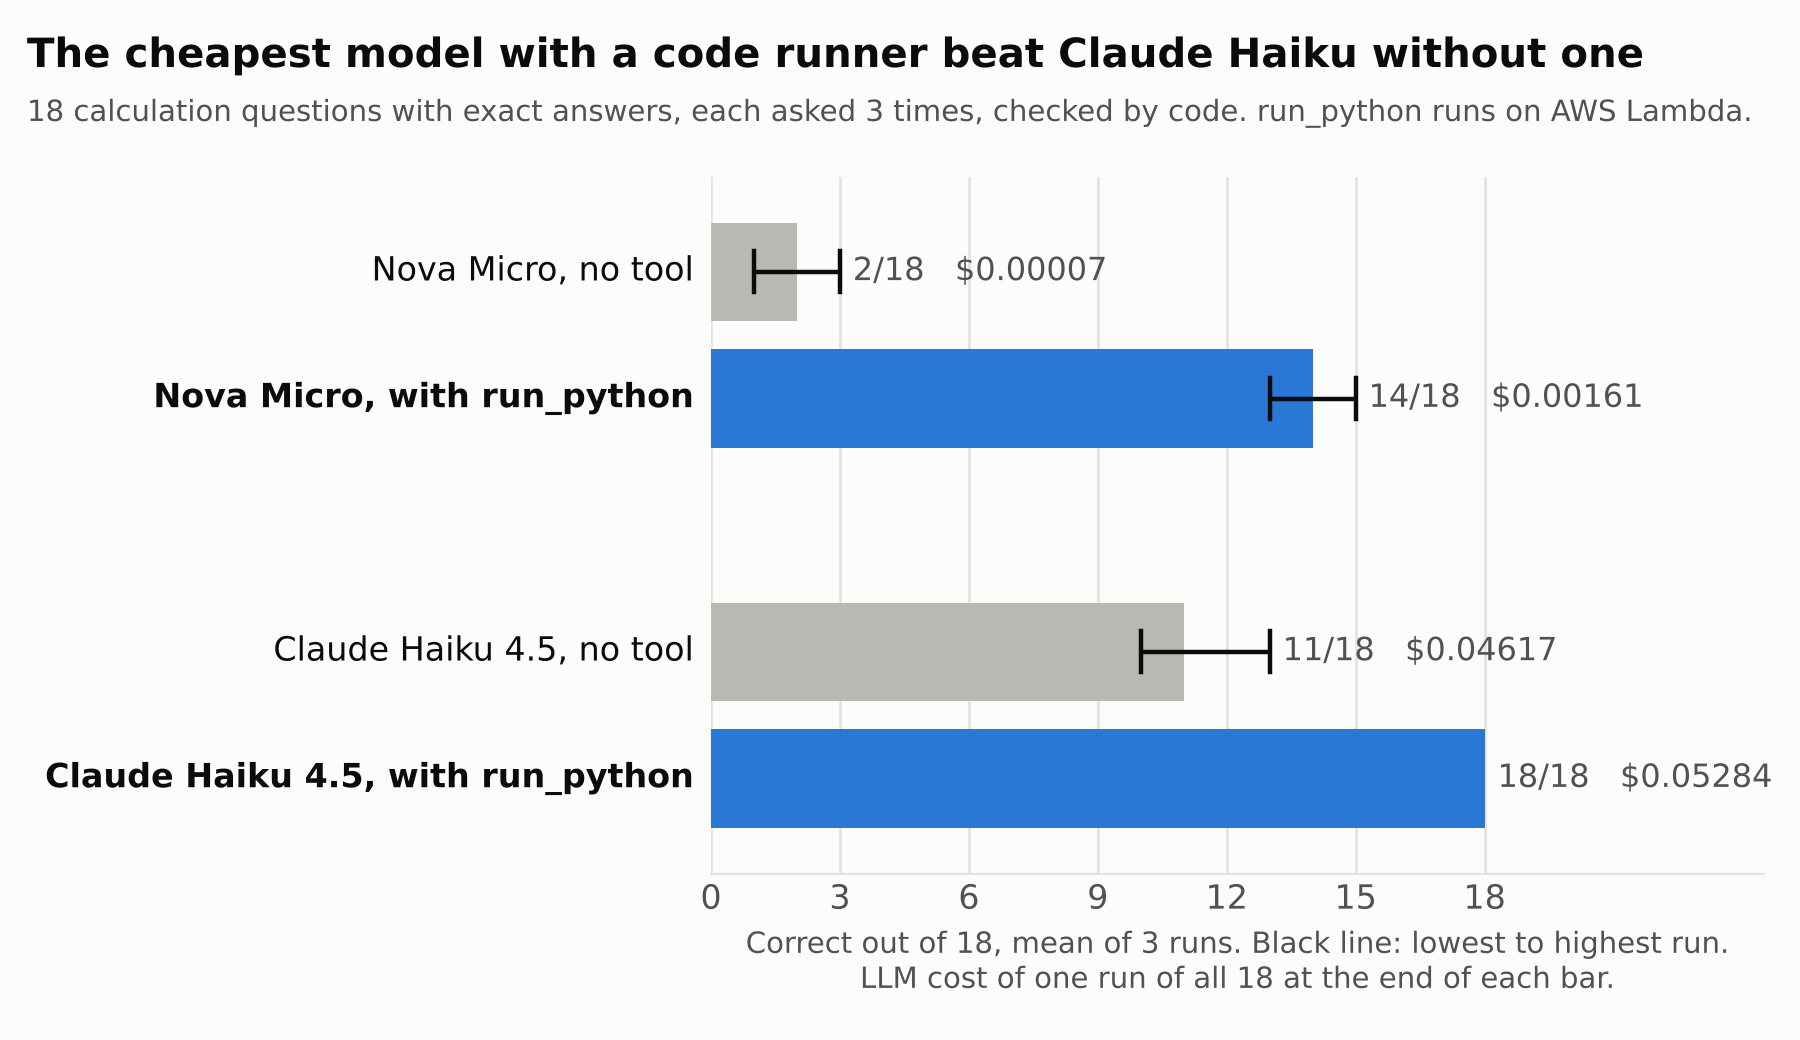

In [7]:
rows = [json.loads(line) for line in (ROOT / "bench" / "reported" / "tool-repeat3-results.jsonl").read_text().splitlines() if line.strip()]
configs = list(dict.fromkeys((r["model"], r["tool"]) for r in rows))
display(Markdown(summarise(rows, configs).split("## Per question")[0]))
display(Image(filename=str(ROOT / "docs" / "tool-before-after.png"), width=760))

In [8]:
def runs_of(model_part, tool):
    mine = [r for r in rows if model_part in r["model"] and r["tool"] == tool]
    return [sum(r["correct"] for r in mine if r["rep"] == rep) for rep in range(3)], sum(r["cost"] for r in mine) / 3

nova_on, nova_cost = runs_of("nova", True)
haiku_off, haiku_cost = runs_of("haiku", False)
print(f"Nova Micro + run_python, per run: {nova_on}   cost per run ${nova_cost:.5f}")
print(f"Claude Haiku, no tool, per run:   {haiku_off}   cost per run ${haiku_cost:.5f}  ({haiku_cost / nova_cost:.0f}x)")
print(f"Nova's worst run with the tool ({min(nova_on)}) vs Haiku's best without it ({max(haiku_off)})")

Nova Micro + run_python, per run: [15, 13, 14]   cost per run $0.00161
Claude Haiku, no tool, per run:   [10, 13, 10]   cost per run $0.04617  (29x)
Nova's worst run with the tool (13) vs Haiku's best without it (13)


## 4. Where the tool made the difference

For each model, the questions it got right more often with the tool than without, out of 3 runs, and one of its answers without the tool.

In [9]:
lines = ["| Question | Model | Right without / with the tool | A wrong answer without | Answer |", "| --- | --- | :---: | ---: | ---: |"]
for qid in dict.fromkeys(r["id"] for r in rows):
    for model in dict.fromkeys(r["model"] for r in rows):
        off = [r for r in rows if r["id"] == qid and r["model"] == model and not r["tool"]]
        on = [r for r in rows if r["id"] == qid and r["model"] == model and r["tool"]]
        right_off, right_on = sum(r["correct"] for r in off), sum(r["correct"] for r in on)
        if right_on > right_off:
            wrong = next((r["predicted"] for r in off if not r["correct"]), "")
            lines.append(f"| `{qid}` {off[0]['kind']} | {short(model)} | {right_off}/3 → {right_on}/3 | {wrong} | {off[0]['answer']} |")
display(Markdown("\n".join(lines)))

| Question | Model | Right without / with the tool | A wrong answer without | Answer |
| --- | --- | :---: | ---: | ---: |
| `calc-01` finance | claude-haiku-4-5-20251001-v1 | 0/3 → 3/3 | 240984.2 | 260463.33 |
| `calc-01` finance | escalator | 0/3 → 3/3 | 261813.9 | 260463.33 |
| `calc-02` finance | nova-micro-v1 | 0/3 → 3/3 | 377.0 | 386.66 |
| `calc-03` finance | nova-micro-v1 | 0/3 → 1/3 | 15892.61 | 13678.52 |
| `calc-03` finance | claude-haiku-4-5-20251001-v1 | 0/3 → 3/3 | 13498.59 | 13678.52 |
| `calc-03` finance | escalator | 0/3 → 3/3 | 13498.58 | 13678.52 |
| `calc-04` arithmetic | nova-micro-v1 | 0/3 → 3/3 | 359405054.0 | 361105294 |
| `calc-04` arithmetic | claude-haiku-4-5-20251001-v1 | 0/3 → 3/3 | 361055594.0 | 361105294 |
| `calc-04` arithmetic | escalator | 0/3 → 3/3 | 361089794.0 | 361105294 |
| `calc-05` arithmetic | nova-micro-v1 | 0/3 → 1/3 | 3513.314 | 1111.111 |
| `calc-05` arithmetic | claude-haiku-4-5-20251001-v1 | 1/3 → 3/3 | 1111.119 | 1111.111 |
| `calc-05` arithmetic | escalator | 1/3 → 3/3 | 1111.116 | 1111.111 |
| `calc-06` arithmetic | nova-micro-v1 | 1/3 → 3/3 | 64.0 | 16 |
| `calc-07` arithmetic | nova-micro-v1 | 0/3 → 3/3 | 137.0 | 115 |
| `calc-08` dates | nova-micro-v1 | 0/3 → 3/3 | 272.0 | 301 |
| `calc-08` dates | escalator | 2/3 → 3/3 | 271.0 | 301 |
| `calc-09` dates | nova-micro-v1 | 2/3 → 3/3 | 4.0 | 2 |
| `calc-09` dates | claude-haiku-4-5-20251001-v1 | 0/3 → 3/3 | 3.0 | 2 |
| `calc-09` dates | escalator | 1/3 → 3/3 | 3.0 | 2 |
| `calc-11` counting | nova-micro-v1 | 0/3 → 3/3 | 784.0 | 1229 |
| `calc-12` counting | nova-micro-v1 | 0/3 → 3/3 | 7.0 | 18 |
| `calc-12` counting | claude-haiku-4-5-20251001-v1 | 1/3 → 3/3 | 20.0 | 18 |
| `calc-12` counting | escalator | 0/3 → 3/3 | 17.0 | 18 |
| `calc-13` counting | nova-micro-v1 | 0/3 → 2/3 | 292.0 | 242 |
| `calc-14` counting | nova-micro-v1 | 0/3 → 3/3 | 102334155.0 | 1548008755920 |
| `calc-15` code | nova-micro-v1 | 0/3 → 3/3 | 340034.0 | 112761 |
| `calc-15` code | claude-haiku-4-5-20251001-v1 | 0/3 → 3/3 | 166650.0 | 112761 |
| `calc-15` code | escalator | 1/3 → 3/3 | 111069.0 | 112761 |
| `calc-16` code | nova-micro-v1 | 0/3 → 3/3 | 10.0 | 111 |
| `calc-18` statistics | nova-micro-v1 | 0/3 → 3/3 | 7.5184 | 7.12 |
| `calc-18` statistics | claude-haiku-4-5-20251001-v1 | 1/3 → 3/3 | 7.1168 | 7.12 |

## 5. What still fails

Nova Micro's misses with the tool. Each row shows the last program it ran and what that printed, then the ANSWER line it wrote.

In [10]:
for r in rows:
    if "nova" in r["model"] and r["tool"] and not r["correct"]:
        last = r["runs"][-1] if r["runs"] else {"code": "(no run)", "result": {"stdout": ""}}
        printed = (last["result"].get("stdout") or last["result"].get("stderr") or "").strip().splitlines()
        print(f"{r['id']} run {r['rep']}: expected {r['answer']}, answered {r['predicted']} after {r['tool_calls']} code run(s)")
        print("   last program printed:", printed[-1] if printed else "(nothing)")

calc-01 run 0: expected 260463.33, answered 380463.0 after 2 code run(s)
   last program printed: 380463.33
calc-10 run 0: expected 76127, answered 76128.0 after 1 code run(s)
   last program printed: 76128
calc-17 run 0: expected 14.7, answered 14.802 after 1 code run(s)
   last program printed: 14.802
calc-01 run 1: expected 260463.33, answered 260463.2 after 2 code run(s)
   last program printed: 260463 2
calc-03 run 1: expected 13678.52, answered 13679.2 after 2 code run(s)
   last program printed: 13679 2
calc-05 run 1: expected 1111.111, answered 1111.0 after 1 code run(s)
   last program printed: 1111.111
calc-13 run 1: expected 242, answered 67.0 after 1 code run(s)
   last program printed: 67
calc-17 run 1: expected 14.7, answered 148003.0 after 2 code run(s)
   last program printed: 14.8003
calc-01 run 2: expected 260463.33, answered 262482.7 after 1 code run(s)
   last program printed: 262482.7
calc-03 run 2: expected 13678.52, answered 1367852.0 after 2 code run(s)
   last 

## 6. Two problems the 3 runs found

**A runaway loop.** One answer called the tool 122 times. The model had sent a whole program on one line with the two characters `\n` instead of line breaks, got a `SyntaxError`, and sent the same program again 121 times:

In [11]:
worst = max(rows, key=lambda r: r["tool_calls"])
print(f"{worst['id']} ({short(worst['model'])}, {worst['path']}): {worst['tool_calls']} code runs, ${worst['cost']:.4f}")
print("program as sent:", repr(worst["runs"][0]["code"]))
print("error:", worst["runs"][0]["result"]["stderr"].strip().splitlines()[-1])
print("identical resends:", sum(run["code"] == worst["runs"][0]["code"] for run in worst["runs"]) - 1)

calc-14 (escalator, escalated): 122 code runs, $0.0738
program as sent: 'print(f(60))\\nf = lambda n: 1 if n <= 2 else f(n-1) + f(n-2)'
error: SyntaxError: unexpected character after line continuation character
identical resends: 0


Two fixes. The tool now repairs this mistake before running the code (`fix_escaped_newlines`): it swaps `\n` for real line breaks, but only when the program doesn't compile as sent and does compile after the swap. That same program now gets a real error the model can act on:

In [12]:
fixed = fix_escaped_newlines(worst["runs"][0]["code"])
print(fixed)
print("->", handler({"code": fixed})["stderr"].strip().splitlines()[-1])

print(f(60))
f = lambda n: 1 if n <= 2 else f(n-1) + f(n-2)
-> NameError: name 'f' is not defined


And `bedrock_call` passes a `RunBudget` hook to the Strands agent, which cancels tool calls after 6 per answer and tells the model to answer from what it has:

In [13]:
from types import SimpleNamespace
budget = RunBudget(limit=6)
calls = [SimpleNamespace(cancel_tool=False) for _ in range(8)]
for call in calls:
    budget.check(call)            # Strands calls this before every tool call (BeforeToolCallEvent)
print("cancelled:", [bool(c.cancel_tool) for c in calls])
print(calls[-1].cancel_tool)

cancelled: [False, False, False, False, False, False, True, True]
Limit of 6 code runs reached. Answer now from the outputs you already have.


**The gate doesn't trust tool results.** In the full agent, when the decider sent a question to Nova Micro first, the gate had to decide whether Nova's draft was good enough. It sent almost every draft on to Haiku, including the ones that were right:

In [14]:
drafts = [r for r in rows if r["model"] == "escalator" and r["tool"] and r["path"] in ("escalated", "direct-small")]
kept = sum(r["path"] == "direct-small" for r in drafts)
nova_right = sum(r["correct"] for r in rows if "nova" in r["model"] and r["tool"])
print(f"Nova drafts the gate saw: {len(drafts)}, kept: {kept}, sent to Haiku: {len(drafts) - kept}")
print(f"Nova + run_python on its own was right {nova_right} of 54 times ({nova_right / 54:.0%})")

Nova drafts the gate saw: 18, kept: 1, sent to Haiku: 17
Nova + run_python on its own was right 42 of 54 times (78%)


## 7. Live run (optional)

With `RUN_LIVE = True`, this asks Claude Haiku the investment question through Amazon Bedrock with the real Lambda-backed tool, then prints the code it ran. It needs AWS credentials, Bedrock model access and the deployed function (`python deploy/deploy_run_python.py`).

In [15]:
if RUN_LIVE:
    from escalator.agent import LARGE_MODEL, SYSTEM_PROMPT, bedrock_call

    live_runs = []
    reply = bedrock_call(LARGE_MODEL, SYSTEM_PROMPT,
                         "If I invest $500 a month for 20 years at 7% a year, compounded monthly, what is the final balance?",
                         [make_run_python(log=live_runs)])
    for run in live_runs:
        print(run["code"], "\n->", run["result"]["stdout"])
    print(reply.text, f"\n\n${reply.cost_usd:.6f}, {reply.latency_ms:.0f} ms, ran code {reply.tool_calls}x")
else:
    print("Skipped. Set RUN_LIVE = True to call AWS Lambda and Amazon Bedrock.")

Skipped. Set RUN_LIVE = True to call AWS Lambda and Amazon Bedrock.
